Upload the input image:


Saving pearls.png to pearls.png


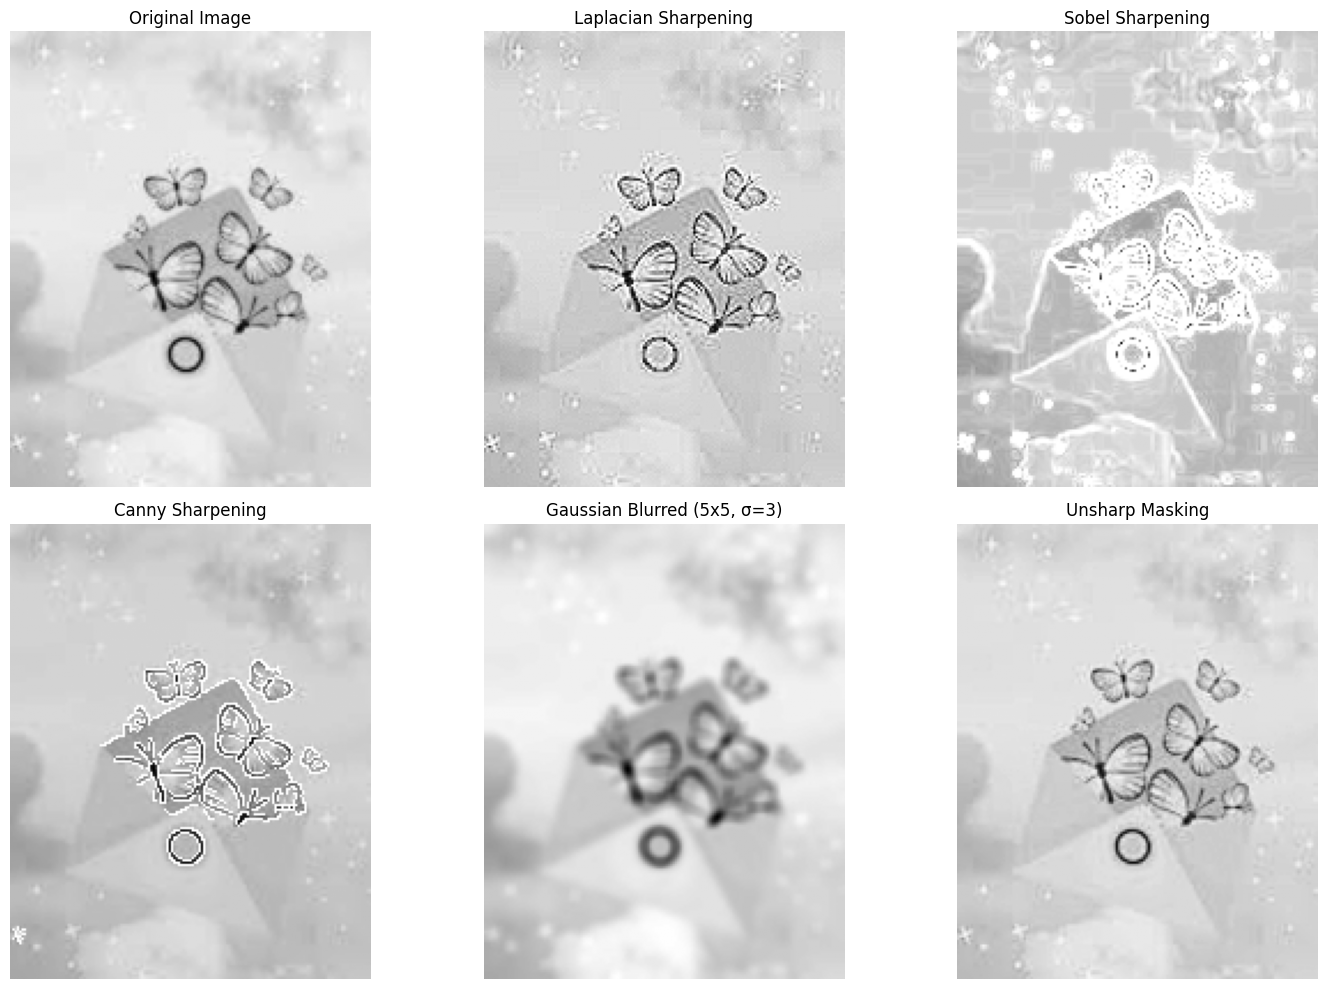

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload input image
print("Upload the input image:")
uploaded = files.upload()

filename = next(iter(uploaded))

# Read image in grayscale
image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

# ---------------------------------------------------
# 1. Sharpening using Laplacian Filter
# ---------------------------------------------------

laplacian = cv2.Laplacian(image, cv2.CV_64F)

# Sharpen image
laplacian_sharpened = cv2.convertScaleAbs(image - laplacian)


# ---------------------------------------------------
# 2. Sharpening using Sobel Gradient Operator
# ---------------------------------------------------

sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

# Calculate gradient magnitude
sobel = cv2.magnitude(sobel_x.astype(np.float32),
                      sobel_y.astype(np.float32))

sobel = cv2.convertScaleAbs(sobel)

# Sharpen using Sobel
sobel_sharpened = cv2.addWeighted(image, 1, sobel, 1, 0)


# ---------------------------------------------------
# 2. Sharpening using Canny Edge Detector
# ---------------------------------------------------

canny = cv2.Canny(image, 100, 200)

# Sharpen using Canny edges
canny_sharpened = cv2.addWeighted(image, 1, canny, 1, 0)


# ---------------------------------------------------
# 3. Unsharp Masking
# Gaussian filter: 5x5, sigma = 3
# ---------------------------------------------------

blurred = cv2.GaussianBlur(image, (5, 5), 3)

# Unsharp masking
unsharp = cv2.addWeighted(image, 1.5, blurred, -0.5, 0)


# ---------------------------------------------------
# Display all results
# ---------------------------------------------------

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(laplacian_sharpened, cmap='gray')
plt.title("Laplacian Sharpening")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sobel_sharpened, cmap='gray')
plt.title("Sobel Sharpening")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(canny_sharpened, cmap='gray')
plt.title("Canny Sharpening")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(blurred, cmap='gray')
plt.title("Gaussian Blurred (5x5, σ=3)")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(unsharp, cmap='gray')
plt.title("Unsharp Masking")
plt.axis("off")

plt.tight_layout()
plt.show()